# 2.04 · Joint, marginal and conditional probability; Bayes' rule

An inversion asks a conditional question: *given* the data we measured, what do we now believe about the
parameters? This notebook builds the three operations every Bayesian calculation is made of (joint, marginal,
conditional), shows why "uncorrelated" does not mean "unrelated", derives Bayes' rule from one line of algebra, and
ends with the most useful result in the whole curriculum: conditioning a joint Gaussian of parameters and data gives
the posterior directly, and the formula contains the **Kalman gain**.

**Words this notebook defines:** joint distribution, marginal (projection), conditional (slice and renormalise),
independence, correlation, product rule, law of total probability, Bayes' rule, base rate, odds, likelihood ratio,
joint Gaussian of parameters and data, conditional mean, Kalman gain.

**Before this:** [2.01](2-01_basics.ipynb), [2.03](2-03_probability_distributions.ipynb). · **You will be able to:** marginalise and condition a joint distribution; show why
uncorrelated is not independent; derive and use Bayes' rule, including base rates; condition a joint Gaussian and
read the Kalman gain as a trust ratio. · **Optional sections:** none; section 5 uses matrices (primer: 2.06).

**Problems in this notebook**

| example | unknowns | data | forward model | linear? |
|---|---|---|---|---|
| common-mode noise at two GPS stations (sections 1-2) | 2 noise values per day | simulated days | none | – |
| a datum that sees only the square of the unknown (section 3) | 1 | 1 | $d = m^2$ + noise | nonlinear |
| a slow-slip detector (section 4) | 1 yes/no state | 1 or 2 detector flags | detection probabilities | – |
| slip on one patch seen by one station (section 5) | 1 | 1 | $d = 2m$ + noise | linear |

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent))

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, Rectangle
from scipy import stats

import bayeskit as bk
from bayeskit import plotting as BP, style as S

rng = np.random.default_rng(2)
C1, C2, C3, C4 = S.BLUE, S.ORANGE, S.AQUA, S.VIOLET

## 1. Joint, marginal, conditional

**In plain words.** Two nearby GPS stations share part of their daily error (the same orbit and atmosphere errors
affect both), so when station A reads high, station B tends to read high too. The **joint distribution** describes
both numbers together: a cloud of daily pairs. The **marginal** of B is what you get if you ignore A: squash the cloud
onto B's axis. The **conditional** of B given A is what you get if you *know* A: keep only the days with that value of
A (a thin slice of the cloud) and look at B within it. Knowing A makes B more predictable; that is what common-mode
filtering (removing the part of the error that nearby stations share) exploits.

**Precisely.** For a joint density $p(a, b)$:
$$p(b) = \int p(a, b)\,da \quad\text{(marginal)}, \qquad p(b \mid a) = \frac{p(a, b)}{p(a)} \quad\text{(conditional)}.$$
For a bivariate Gaussian with sds $\sigma_A, \sigma_B$ and correlation $\rho$:
$$b \mid a \;\sim\; N\!\left(\rho\frac{\sigma_B}{\sigma_A}\,a,\;\; \sigma_B^2(1-\rho^2)\right).$$

saved figures/2-04_joint_marginal_conditional.png


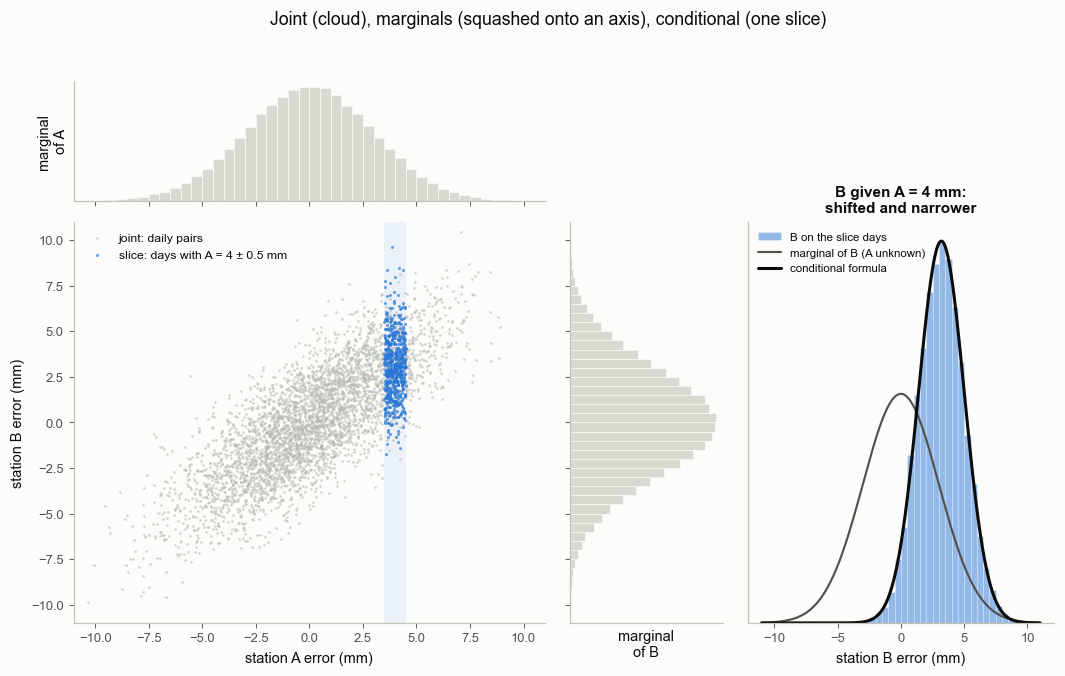

In [2]:
sA = sB = 3.0                                                 # daily east error sd at each station, mm
rho = 0.8                                                     # shared (common-mode) part
Cab = np.array([[sA ** 2, rho * sA * sB], [rho * sA * sB, sB ** 2]])
AB = (np.linalg.cholesky(Cab) @ rng.standard_normal((2, 200_000))).T
a0, half = 4.0, 0.5                                           # condition on station A reading 4 mm (+-0.5 mm slice)
inslice = np.abs(AB[:, 0] - a0) < half

fig = plt.figure(figsize=(11.5, 6.4))
gs = fig.add_gridspec(2, 3, width_ratios=[4, 1.3, 2.6], height_ratios=[1.2, 4], hspace=0.08, wspace=0.08)
ax = fig.add_subplot(gs[1, 0])
axt = fig.add_subplot(gs[0, 0], sharex=ax)
axr = fig.add_subplot(gs[1, 1], sharey=ax)
axc = fig.add_subplot(gs[1, 2])
show = rng.choice(AB.shape[0], 4000, replace=False)
ax.scatter(AB[show, 0], AB[show, 1], s=3, color="#b9b8b0", alpha=0.6, lw=0, label="joint: daily pairs")
ax.scatter(AB[inslice, 0][:600], AB[inslice, 1][:600], s=4, color=C1, alpha=0.7, lw=0, label=f"slice: days with A = {a0:g} ± {half:g} mm")
ax.axvspan(a0 - half, a0 + half, color=C1, alpha=0.08, lw=0)
ax.set_xlim(-11, 11); ax.set_ylim(-11, 11)
ax.set_xlabel("station A error (mm)"); ax.set_ylabel("station B error (mm)")
ax.legend(fontsize=8, loc="upper left")
bins = np.arange(-11, 11.01, 0.5)
axt.hist(AB[:, 0], bins=bins, density=True, color="#d9d8d1", edgecolor=S.SURFACE, lw=0.4)
axt.set_ylabel("marginal\nof A"); axt.tick_params(labelbottom=False); axt.set_yticks([])
axr.hist(AB[:, 1], bins=bins, density=True, orientation="horizontal", color="#d9d8d1", edgecolor=S.SURFACE, lw=0.4)
axr.set_xlabel("marginal\nof B"); axr.tick_params(labelleft=False); axr.set_xticks([])
bb = np.linspace(-11, 11, 600)
axc.hist(AB[inslice, 1], bins=bins, density=True, color=C1, alpha=0.5, edgecolor=S.SURFACE, lw=0.4, label="B on the slice days")
axc.plot(bb, stats.norm(0, sB).pdf(bb), color=S.INK2, lw=1.4, label="marginal of B (A unknown)")
axc.plot(bb, stats.norm(rho * sB / sA * a0, sB * np.sqrt(1 - rho ** 2)).pdf(bb), color=S.INK, lw=2, label="conditional formula")
axc.set_xlabel("station B error (mm)"); axc.set_yticks([])
axc.set_title(f"B given A = {a0:g} mm:\nshifted and narrower", fontsize=10)
axc.legend(fontsize=7.5, loc="upper left")
fig.suptitle("Joint (cloud), marginals (squashed onto an axis), conditional (one slice)", fontsize=11.5, y=0.98)
bk.savefig(fig, "2-04_joint_marginal_conditional")
plt.show()

**How to read it.** Grey cloud: every simulated day as one point. The histograms on the edges are the marginals:
each station alone, both with the same spread. The blue slice keeps only the days when A read about 4 mm; on those
days B is centred higher and spread less (right panel), and the conditional formula matches the counted histogram.

**Worked example.** With $\sigma_A = \sigma_B$ = 3 mm and $\rho$ = 0.8, what do we expect from B on a day when A
reads 4 mm?
1. conditional mean $= \rho\,(\sigma_B/\sigma_A)\,a$;
2. conditional sd $= \sigma_B\sqrt{1-\rho^2}$;
3. check against the days in the slice.

In [3]:
print(f"step 1: conditional mean = {rho} x ({sB}/{sA}) x {a0} = {rho * sB / sA * a0:.3f} mm")
print(f"step 2: conditional sd   = {sB} x sqrt(1 - {rho}^2) = {sB * np.sqrt(1 - rho ** 2):.3f} mm   (marginal sd {sB} mm)")
print(f"step 3: the {inslice.sum()} slice days: mean {AB[inslice, 1].mean():.3f} mm, sd {AB[inslice, 1].std():.3f} mm "
      f"(the +-{half} mm slice width adds a little)")

step 1: conditional mean = 0.8 x (3.0/3.0) x 4.0 = 3.200 mm
step 2: conditional sd   = 3.0 x sqrt(1 - 0.8^2) = 1.800 mm   (marginal sd 3.0 mm)
step 3: the 11044 slice days: mean 3.178 mm, sd 1.822 mm (the +-0.5 mm slice width adds a little)


**Common misreadings.**
* "The marginal is the distribution at the most likely value of the other variable." No: the marginal averages over
  all values of the other variable (squashing), the conditional fixes it (slicing). For a posterior, a marginal of one
  slip patch includes all possible values of its neighbours.
* "Conditioning always shifts the mean." It always changes the distribution unless the variables are independent
  (next section); with $a = 0$ the mean stays at 0 and only the width shrinks.

**In geodesy.** Common-mode filtering subtracts the part of a station's error that is predictable from its
neighbours, which is the conditional mean above; the remaining scatter is the conditional sd.

## 2. Independence

**In plain words.** Two quantities are **independent** if knowing one tells you nothing about the other: every slice
of the cloud looks the same. Then the joint is simply the product of the marginals.

**Precisely.** $a$ and $b$ are independent if and only if $p(a, b) = p(a)\,p(b)$, equivalently
$p(b \mid a) = p(b)$ for every $a$. For Gaussians, independence is the same as zero correlation; in general it is
a much stronger statement (section 3).

saved figures/2-04_independence.png


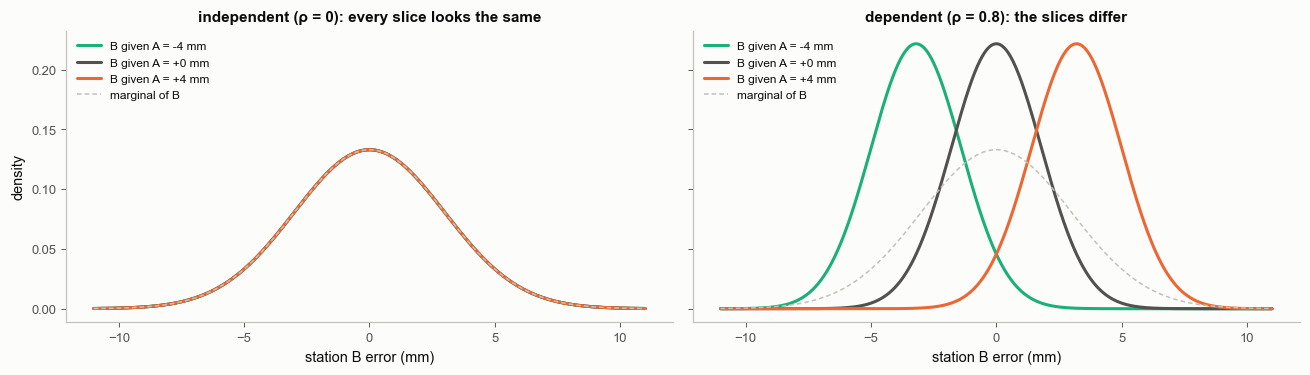

In [4]:
fig, axs = plt.subplots(1, 2, figsize=(12, 3.5), sharey=True)
for ax, r_, title in [(axs[0], 0.0, "independent (ρ = 0): every slice looks the same"),
                      (axs[1], 0.8, "dependent (ρ = 0.8): the slices differ")]:
    for a_, col in zip([-4.0, 0.0, 4.0], [C3, S.INK2, C2]):
        ax.plot(bb, stats.norm(r_ * a_, sB * np.sqrt(1 - r_ ** 2)).pdf(bb), color=col, lw=2, label=f"B given A = {a_:+g} mm")
    ax.plot(bb, stats.norm(0, sB).pdf(bb), color=S.AXIS, lw=1, ls=(0, (3, 2)), label="marginal of B")
    ax.set_xlabel("station B error (mm)"); ax.set_title(title, fontsize=10)
    ax.legend(fontsize=7.8, loc="upper left")
axs[0].set_ylabel("density")
fig.tight_layout()
bk.savefig(fig, "2-04_independence")
plt.show()

**How to read it.** Left: the three conditional curves lie on top of each other and on the marginal: A tells you
nothing about B. Right: each value of A moves and narrows the distribution of B.

**Worked example.** Independence lets you multiply: the probability that both stations exceed +3 mm on the same day.
1. independent: $P(A > 3)\,P(B > 3)$;
2. correlated ($\rho$ = 0.8): count the days in the simulated cloud (the product rule no longer applies).

In [5]:
p1 = stats.norm(0, sA).sf(3.0)
print(f"step 1: if independent: {p1:.4f} x {p1:.4f} = {p1 * p1:.4f}")
print(f"step 2: with rho = 0.8 (counted over 200,000 simulated days): {np.mean((AB[:, 0] > 3) & (AB[:, 1] > 3)):.4f}")

step 1: if independent: 0.1587 x 0.1587 = 0.0252
step 2: with rho = 0.8 (counted over 200,000 simulated days): 0.0982


**Common misreadings.**
* "Independent errors can be added in quadrature" (combined as the square root of the sum of their squares) is true;
  "correlated errors can too" is not. Section 2's worked
  example shows how badly the product rule fails when it is applied to dependent errors.

**In geodesy.** A diagonal $\mathbf C_d$ (zeros off the diagonal, 2.03) is a statement of independence between data,
at least for Gaussian errors. Daily GPS positions with coloured noise (errors correlated from one day to the next) are
not independent from day to day, which is why 2.05 finds that averaging helps less than
$1/\sqrt N$.

## 3. Uncorrelated is not the same as independent

**In plain words.** Correlation measures only straight-line relations. Suppose a datum depends on the *square* of an
unknown, like a distance that cannot tell north from south. Then the datum is completely determined by the unknown,
yet the correlation between them is zero, because positive and negative values of the unknown give the same datum.
Slicing the cloud at a given datum value gives two separate possibilities.

**Precisely.** The correlation $\rho = \mathrm{Cov}(m, d)/(\sigma_m\sigma_d)$ is zero whenever $\mathbb E[(m-\bar m)(d-\bar d)] = 0$.
For $m \sim N(0, 1)$ and $d = m^2$: $\mathrm{Cov}(m, m^2) = \mathbb E[m^3] = 0$, while $p(d \mid m)$ is a spike at $m^2$.

saved figures/2-04_zero_correlation.png


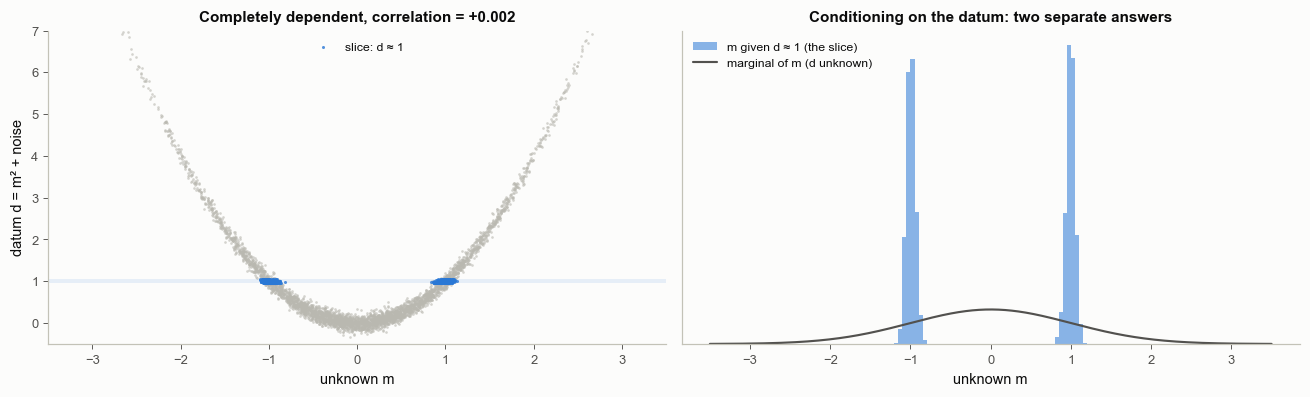

In [6]:
m_ = rng.standard_normal(200_000)
d_ = m_ ** 2 + 0.1 * rng.standard_normal(m_.size)
r_md = np.corrcoef(m_, d_)[0, 1]
d_slice = np.abs(d_ - 1.0) < 0.05
fig, axs = plt.subplots(1, 2, figsize=(12, 3.7))
ax = axs[0]
sh = rng.choice(m_.size, 4000, replace=False)
ax.scatter(m_[sh], d_[sh], s=3, color="#b9b8b0", alpha=0.6, lw=0)
ax.scatter(m_[d_slice][:600], d_[d_slice][:600], s=4, color=C1, alpha=0.8, lw=0, label="slice: d ≈ 1")
ax.axhspan(0.95, 1.05, color=C1, alpha=0.1, lw=0)
ax.set_xlabel("unknown m"); ax.set_ylabel("datum d = m² + noise"); ax.set_xlim(-3.5, 3.5); ax.set_ylim(-0.5, 7)
ax.set_title(f"Completely dependent, correlation = {r_md:+.3f}", fontsize=10)
ax.legend(fontsize=8, loc="upper center")
ax = axs[1]
ax.hist(m_[d_slice], bins=np.linspace(-3.5, 3.5, 141), density=True, color=C1, alpha=0.55, label="m given d ≈ 1 (the slice)")
mm = np.linspace(-3.5, 3.5, 600)
ax.plot(mm, stats.norm.pdf(mm), color=S.INK2, lw=1.4, label="marginal of m (d unknown)")
ax.set_xlabel("unknown m"); ax.set_yticks([]); ax.legend(fontsize=8, loc="upper left")
ax.set_title("Conditioning on the datum: two separate answers", fontsize=10)
fig.tight_layout()
bk.savefig(fig, "2-04_zero_correlation")
plt.show()

**How to read it.** Left: a perfect parabola, and a correlation that is zero to within sampling noise (in the
title). Right: given $d \approx 1$, the unknown is near $+1$ or near $-1$, never in between. This is the two-island
posterior of notebook 2.01 · Basics in one dimension: two stations on a line measure distances, and a distance is
blind to the sign of the north coordinate.

**Worked example.** Compute the correlation of $m$ and $m^2$ from the formula and from the simulated pairs.
1. $\mathrm{Cov}(m, m^2) = \mathbb E[m^3] - \mathbb E[m]\,\mathbb E[m^2]$;
2. for a symmetric $m$ both terms vanish;
3. count.

In [7]:
print(f"step 1-2: E[m^3] for a standard Gaussian = {stats.norm.moment(3):.1f}, E[m] = 0 -> Cov(m, m^2) = 0")
print(f"step 3: correlation from 200,000 simulated pairs = {r_md:+.4f}  (sampling noise of order 1/sqrt(N) = {1 / np.sqrt(m_.size):.4f})")
print(f"        share of the slice d = 1 +- 0.05 with m > 0: {np.mean(m_[d_slice] > 0):.3f}")

step 1-2: E[m^3] for a standard Gaussian = 0.0, E[m] = 0 -> Cov(m, m^2) = 0
step 3: correlation from 200,000 simulated pairs = +0.0019  (sampling noise of order 1/sqrt(N) = 0.0022)
        share of the slice d = 1 +- 0.05 with m > 0: 0.512


**Common misreadings.**
* "The posterior correlation between two parameters is near zero, so they are unrelated." A ring- or two-island
  posterior can have zero correlation and complete dependence. Look at the pairs plot, not only the correlation
  matrix.

**In geodesy.** Polarity, sign and mirror ambiguities (which side of a station; which of the two *nodal planes* of an
earthquake's focal mechanism, the two fault orientations that radiate the same first-motion pattern) produce exactly
this structure.

## 4. Bayes' rule, from one line of algebra

**In plain words.** The probability that two things are both true can be written two ways: "A, and then B given A",
or "B, and then A given B". Setting the two equal and dividing gives Bayes' rule, which turns a probability you know
(how often the data look like this when the hypothesis is true) into the one you want (how probable the hypothesis
is now that you have seen the data). The ingredient people forget is the **base rate**: how common the hypothesis was
beforehand.

**Precisely.** Product rule $P(A, B) = P(A \mid B)\,P(B) = P(B \mid A)\,P(A)$, hence
$$P(A \mid B) = \frac{P(B \mid A)\,P(A)}{P(B)}, \qquad P(B) = \sum_{A'} P(B \mid A')\,P(A') \quad\text{(total probability)}.$$
In odds form: posterior odds = prior odds × likelihood ratio, $\dfrac{P(A\mid B)}{P(\bar A\mid B)} = \dfrac{P(A)}{P(\bar A)}\cdot\dfrac{P(B\mid A)}{P(B\mid\bar A)}$.
For continuous parameters the same rule reads $p(\mathbf m \mid \mathbf d) \propto p(\mathbf d \mid \mathbf m)\,p(\mathbf m)$.

The example: a *slow-slip event* is a fault slipping over days to months without an earthquake, visible only in
geodetic time series. An automatic detector scans each week of GPS data and either flags it or not.

saved figures/2-04_bayes_tree.png


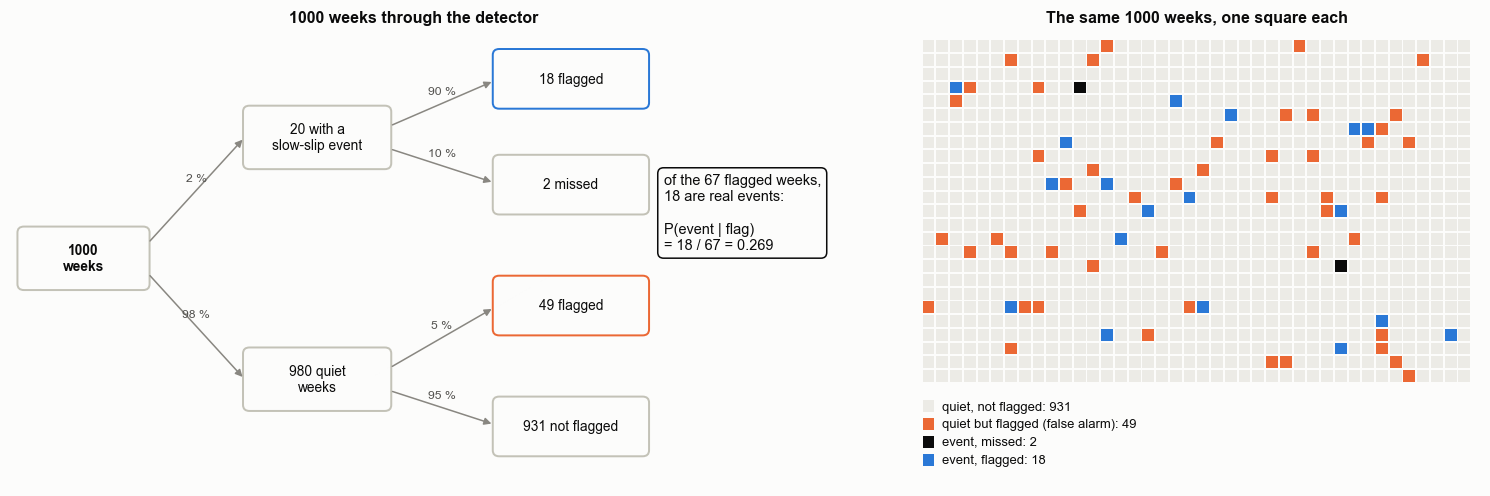

In [8]:
p_ev, p_flag_ev, p_flag_quiet = 0.02, 0.90, 0.05              # inputs: base rate, hit rate, false-alarm rate
weeks = 1000
n_ev = weeks * p_ev; n_q = weeks - n_ev
hit, miss = n_ev * p_flag_ev, n_ev * (1 - p_flag_ev)
fa, cr = n_q * p_flag_quiet, n_q * (1 - p_flag_quiet)
post = hit / (hit + fa)

fig, axs = plt.subplots(1, 2, figsize=(14, 4.6), gridspec_kw=dict(width_ratios=[1.25, 1]))
ax = axs[0]; ax.axis("off"); ax.set_xlim(0, 10); ax.set_ylim(0, 6)


def node(x, y, w, h, text, ec=S.AXIS, bold=False):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.02,rounding_size=0.08", fc=S.SURFACE, ec=ec, lw=1.3))
    ax.text(x + w / 2, y + h / 2, text, ha="center", va="center", fontsize=9, fontweight="bold" if bold else "normal")


def edge(x0, y0, x1, y1, lab):
    ax.annotate("", xy=(x1, y1), xytext=(x0, y0), arrowprops=dict(arrowstyle="-|>", color=S.MUTED, lw=1))
    ax.text((x0 + x1) / 2, (y0 + y1) / 2 + 0.12, lab, fontsize=8, color=S.INK2, ha="center")


node(0.1, 2.6, 1.6, 0.8, f"{weeks}\nweeks", bold=True)
node(2.9, 4.2, 1.8, 0.8, f"{n_ev:.0f} with a\nslow-slip event")
node(2.9, 1.0, 1.8, 0.8, f"{n_q:.0f} quiet\nweeks")
edge(1.7, 3.2, 2.9, 4.6, f"{100 * p_ev:.0f} %")
edge(1.7, 2.8, 2.9, 1.4, f"{100 * (1 - p_ev):.0f} %")
node(6.0, 5.0, 1.9, 0.75, f"{hit:.0f} flagged", ec=C1)
node(6.0, 3.6, 1.9, 0.75, f"{miss:.0f} missed")
node(6.0, 2.0, 1.9, 0.75, f"{fa:.0f} flagged", ec=C2)
node(6.0, 0.4, 1.9, 0.75, f"{cr:.0f} not flagged")
edge(4.7, 4.75, 6.0, 5.35, f"{100 * p_flag_ev:.0f} %")
edge(4.7, 4.45, 6.0, 4.0, f"{100 * (1 - p_flag_ev):.0f} %")
edge(4.7, 1.55, 6.0, 2.35, f"{100 * p_flag_quiet:.0f} %")
edge(4.7, 1.25, 6.0, 0.8, f"{100 * (1 - p_flag_quiet):.0f} %")
ax.text(8.1, 3.6, f"of the {hit + fa:.0f} flagged weeks,\n{hit:.0f} are real events:\n\nP(event | flag)\n= {hit:.0f} / {hit + fa:.0f} = {post:.3f}",
        fontsize=9.5, va="center", ha="left", bbox=dict(boxstyle="round,pad=0.4", fc=S.SURFACE, ec=S.INK, lw=1))
ax.set_title("1000 weeks through the detector", fontsize=10.5)
ax = axs[1]
grid = np.zeros(weeks, int)                                  # 0 quiet, 1 false alarm, 2 missed event, 3 caught event
grid[: int(fa)] = 1
grid[int(fa): int(fa + miss)] = 2
grid[int(fa + miss): int(fa + miss + hit)] = 3
grid = rng.permutation(grid)
cols_g = {0: "#ecebe6", 1: C2, 2: S.INK, 3: C1}
labs_g = {0: "quiet, not flagged", 1: "quiet but flagged (false alarm)", 2: "event, missed", 3: "event, flagged"}
for k in range(weeks):
    r_, c_ = divmod(k, 40)
    ax.add_patch(Rectangle((c_, 24 - r_), 0.86, 0.86, color=cols_g[grid[k]], lw=0))
for g_, lab in labs_g.items():
    ax.add_patch(Rectangle((0, -2.2 - 1.3 * g_), 0.86, 0.86, color=cols_g[g_], lw=0))
    ax.text(1.4, -1.8 - 1.3 * g_, f"{lab}: {np.sum(grid == g_)}", fontsize=8.5, va="center")
ax.set_xlim(-0.5, 40.5); ax.set_ylim(-7.5, 25.5); ax.set_aspect("equal"); ax.axis("off")
ax.set_title("The same 1000 weeks, one square each", fontsize=10.5)
fig.tight_layout()
bk.savefig(fig, "2-04_bayes_tree")
plt.show()

**How to read it.** The detector catches most events, yet most flags are false alarms, because quiet weeks are so
much more common (the orange squares outnumber the blue ones). The answer printed in the box is what Bayes' rule
computes.

**Worked example.** Inputs: 2 % of weeks contain an event; the detector flags 90 % of event weeks and 5 % of quiet
weeks.
1. total probability of a flag: $P(F) = P(F\mid E)P(E) + P(F\mid Q)P(Q)$;
2. Bayes: $P(E\mid F) = P(F\mid E)P(E)/P(F)$;
3. odds form: prior odds × likelihood ratio;
4. a second, independent detector also flags: the posterior from step 2 becomes the new prior;
5. check by simulating a million weeks.

In [9]:
pF = p_flag_ev * p_ev + p_flag_quiet * (1 - p_ev)
pEF = p_flag_ev * p_ev / pF
odds = (p_ev / (1 - p_ev)) * (p_flag_ev / p_flag_quiet)
print(f"step 1: P(flag) = {p_flag_ev}*{p_ev} + {p_flag_quiet}*{1 - p_ev} = {pF:.4f}")
print(f"step 2: P(event | flag) = {p_flag_ev}*{p_ev} / {pF:.4f} = {pEF:.4f}")
print(f"step 3: prior odds {p_ev / (1 - p_ev):.4f} x likelihood ratio {p_flag_ev / p_flag_quiet:.1f} = posterior odds {odds:.4f}"
      f" -> probability {odds / (1 + odds):.4f}")
p2 = p_flag_ev * pEF / (p_flag_ev * pEF + p_flag_quiet * (1 - pEF))
print(f"step 4: second detector flags too: P(event | both) = {p2:.4f}   (yesterday's posterior is today's prior)")
N_sim = 1_000_000
ev = rng.uniform(size=N_sim) < p_ev
f1 = np.where(ev, rng.uniform(size=N_sim) < p_flag_ev, rng.uniform(size=N_sim) < p_flag_quiet)
f2 = np.where(ev, rng.uniform(size=N_sim) < p_flag_ev, rng.uniform(size=N_sim) < p_flag_quiet)
print(f"step 5: simulated: P(event | flag) = {ev[f1].mean():.4f},  P(event | both flag) = {ev[f1 & f2].mean():.4f}")

step 1: P(flag) = 0.9*0.02 + 0.05*0.98 = 0.0670
step 2: P(event | flag) = 0.9*0.02 / 0.0670 = 0.2687
step 3: prior odds 0.0204 x likelihood ratio 18.0 = posterior odds 0.3673 -> probability 0.2687
step 4: second detector flags too: P(event | both) = 0.8686   (yesterday's posterior is today's prior)
step 5: simulated: P(event | flag) = 0.2716,  P(event | both flag) = 0.8701


**Common misreadings.**
* "The detector is right 90 % of the time, so a flag means 90 %." That confuses $P(\text{flag}\mid\text{event})$ with
  $P(\text{event}\mid\text{flag})$, the most common error in reasoning with probabilities.
* "The prior is subjective, so leave it out." Leaving it out silently assumes a base rate of 50 %.

**In geodesy.** Every posterior in this tutorial is step 2 with continuous quantities: likelihood (how well a
candidate explains the data) times prior (how plausible it was), renormalised. Step 4, the posterior becoming the next
prior, is the whole idea of the Kalman filter (2.23).

## 5. Conditioning a joint Gaussian: the posterior and the Kalman gain

**In plain words.** Before the measurement, slip on a patch and the displacement it would produce at a station are
uncertain *together*: if the slip is large, the displacement will be large. Their joint distribution is a tilted
ellipse. Making the measurement means keeping only the slice of that ellipse at the observed displacement, and what is
left is the posterior of the slip. For Gaussians the slice is again a Gaussian, and its centre moves along a straight
line as the observed value changes. The slope of that line, how far the estimate moves per unit of surprising data, is
the **Kalman gain**.

**Precisely.** With prior $\mathbf m \sim N(\mathbf m_0, \mathbf C_m)$ ($\mathbf C_m$ is the prior covariance of the
parameters) and $\mathbf d = \mathbf G\mathbf m + \mathbf e$, $\mathbf e \sim N(0, \mathbf C_d)$, the pair
$(\mathbf m, \mathbf d)$ is jointly Gaussian (the block notation, transposes $^\top$ and inverses $^{-1}$ are explained in
2.06; in one dimension every matrix below is an ordinary number, as in the worked example):
$$\begin{pmatrix}\mathbf m\\ \mathbf d\end{pmatrix} \sim N\!\left(\begin{pmatrix}\mathbf m_0\\ \mathbf G\mathbf m_0\end{pmatrix},
\begin{pmatrix}\mathbf C_m & \mathbf C_m\mathbf G^\top\\ \mathbf G\mathbf C_m & \mathbf G\mathbf C_m\mathbf G^\top + \mathbf C_d\end{pmatrix}\right).$$
Conditioning on $\mathbf d$ gives
$$\mathbf m \mid \mathbf d \sim N\big(\mathbf m_0 + \mathbf K(\mathbf d - \mathbf G\mathbf m_0),\;\; \mathbf C_m - \mathbf K\mathbf G\mathbf C_m\big),
\qquad \mathbf K = \mathbf C_m\mathbf G^\top(\mathbf G\mathbf C_m\mathbf G^\top + \mathbf C_d)^{-1}.$$

saved figures/2-04_gaussian_conditioning.png


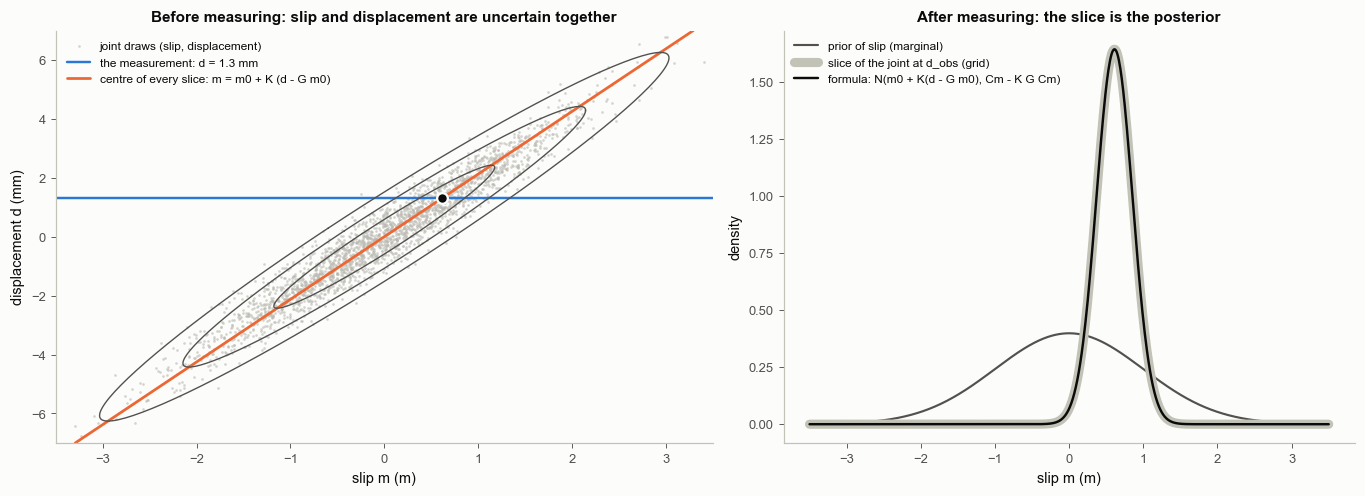

In [10]:
m0, Cm, G, sig = 0.0, 1.0, 2.0, 0.5                          # prior slip N(0, 1) m; d = 2 m + noise (0.5)
d_obs = 1.3
K = Cm * G / (G * Cm * G + sig ** 2)
post_mean, post_var = m0 + K * (d_obs - G * m0), Cm - K * G * Cm
Cj = np.array([[Cm, Cm * G], [G * Cm, G * Cm * G + sig ** 2]])
mg = np.linspace(-3.5, 3.5, 701); dg = np.linspace(-7, 7, 1401)
MM, DD = np.meshgrid(mg, dg)
joint = stats.multivariate_normal([m0, G * m0], Cj).pdf(np.dstack([MM, DD]))
row = joint[np.argmin(np.abs(dg - d_obs))]
row = row / (row.sum() * (mg[1] - mg[0]))                     # the slice, renormalised

fig, axs = plt.subplots(1, 2, figsize=(12.5, 4.6), gridspec_kw=dict(width_ratios=[1.15, 1]))
ax = axs[0]
smp = (np.linalg.cholesky(Cj) @ rng.standard_normal((2, 2500))).T
ax.scatter(smp[:, 0], smp[:, 1], s=3, color="#b9b8b0", alpha=0.6, lw=0, label="joint draws (slip, displacement)")
for qq in (0.5, 0.9, 0.99):
    BP.ellipse(ax, np.array([m0, G * m0]), Cj, nsig=np.sqrt(-2 * np.log(1 - qq)), color=S.INK2, lw=0.9)
ax.axhline(d_obs, color=C1, lw=1.6, label=f"the measurement: d = {d_obs} mm")
dd_line = np.linspace(-7, 7, 2)
ax.plot(m0 + K * (dd_line - G * m0), dd_line, color=C2, lw=1.8, label="centre of every slice: m = m0 + K (d - G m0)")
ax.plot(post_mean, d_obs, "o", color=S.INK, ms=7, mec=S.SURFACE, mew=1.5)
ax.set_xlim(-3.5, 3.5); ax.set_ylim(-7, 7)
ax.set_xlabel("slip m (m)"); ax.set_ylabel("displacement d (mm)")
ax.set_title("Before measuring: slip and displacement are uncertain together", fontsize=10)
ax.legend(fontsize=7.8, loc="upper left")
ax = axs[1]
ax.plot(mg, stats.norm(m0, np.sqrt(Cm)).pdf(mg), color=S.INK2, lw=1.4, label="prior of slip (marginal)")
ax.plot(mg, row, color="#c3c2b7", lw=6, label="slice of the joint at d_obs (grid)")
ax.plot(mg, stats.norm(post_mean, np.sqrt(post_var)).pdf(mg), color=S.INK, lw=1.6, label="formula: N(m0 + K(d - G m0), Cm - K G Cm)")
ax.set_xlabel("slip m (m)"); ax.set_ylabel("density"); ax.legend(fontsize=7.8, loc="upper left")
ax.set_title("After measuring: the slice is the posterior", fontsize=10)
fig.tight_layout()
bk.savefig(fig, "2-04_gaussian_conditioning")
plt.show()

**How to read it.** Left: the grey cloud is every combination of slip and displacement the prior and the noise allow.
The blue line is the measurement; the orange line joins the centres of all possible slices, and its slope (in this
picture, change of slip per change of displacement) is the Kalman gain. Right: the slice computed by brute force on a
grid (thick grey) and the formula (black) coincide.

**Worked example.** Prior slip $m \sim N(0, 1)$ m, one station with $d = 2m + e$, noise sd 0.5 mm, observed
$d$ = 1.3 mm.
1. $K = C_m G / (G C_m G + \sigma^2)$;
2. posterior mean $= m_0 + K(d - G m_0)$;
3. posterior variance $= C_m - K G C_m$, posterior sd its square root;
4. check against the grid slice.

In [11]:
print(f"step 1: K = {Cm}*{G} / ({G}*{Cm}*{G} + {sig}^2) = {K:.6f} m per mm")
print(f"step 2: posterior mean = {m0} + {K:.6f} x ({d_obs} - {G}*{m0}) = {post_mean:.6f} m")
print(f"step 3: posterior variance = {Cm} - {K:.6f}*{G}*{Cm} = {post_var:.6f} m^2  ->  sd {np.sqrt(post_var):.6f} m (prior sd {np.sqrt(Cm)})")
dm_ = mg[1] - mg[0]
gm = (row * mg).sum() * dm_; gs_ = np.sqrt((row * (mg - gm) ** 2).sum() * dm_)
print(f"step 4: grid slice: mean {gm:.6f} m, sd {gs_:.6f} m")

step 1: K = 1.0*2.0 / (2.0*1.0*2.0 + 0.5^2) = 0.470588 m per mm
step 2: posterior mean = 0.0 + 0.470588 x (1.3 - 2.0*0.0) = 0.611765 m
step 3: posterior variance = 1.0 - 0.470588*2.0*1.0 = 0.058824 m^2  ->  sd 0.242536 m (prior sd 1.0)
step 4: grid slice: mean 0.611765 m, sd 0.242536 m


**The slice moves, its width does not.** The animation slides the measured value from low to high. The posterior
slides along the orange line, but its width stays the same: in a linear-Gaussian problem the posterior uncertainty
depends on the noise and the prior, not on what you happened to measure.

GIF size 1.00 MB, 67 frames



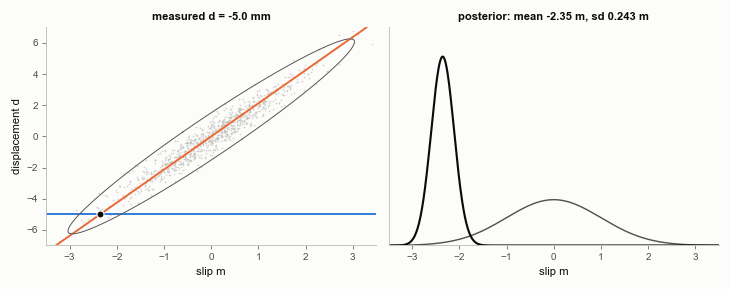

the last frame at full resolution:
saved figures/2-04_slice_moving_final.png


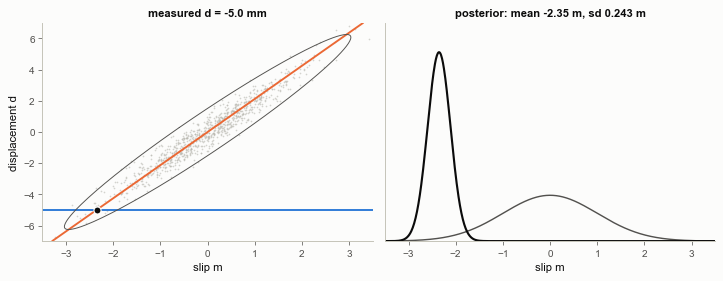

In [12]:
def slice_frame(dv):
    fig, axs = plt.subplots(1, 2, figsize=(8.6, 3.4), dpi=85, gridspec_kw=dict(width_ratios=[1, 1]))
    ax = axs[0]
    ax.scatter(smp[:900, 0], smp[:900, 1], s=2, color="#b9b8b0", alpha=0.6, lw=0)
    BP.ellipse(ax, np.array([m0, G * m0]), Cj, nsig=np.sqrt(-2 * np.log(0.01)), color=S.INK2, lw=0.8)
    ax.plot(m0 + K * (dd_line - G * m0), dd_line, color=C2, lw=1.6)
    ax.axhline(dv, color=C1, lw=1.6)
    pm_ = m0 + K * (dv - G * m0)
    ax.plot(pm_, dv, "o", color=S.INK, ms=6, mec=S.SURFACE)
    ax.set_xlim(-3.5, 3.5); ax.set_ylim(-7, 7); ax.set_xlabel("slip m"); ax.set_ylabel("displacement d")
    ax.set_title(f"measured d = {dv:+.1f} mm", fontsize=9.5)
    ax = axs[1]
    ax.plot(mg, stats.norm(m0, np.sqrt(Cm)).pdf(mg), color=S.INK2, lw=1.2)
    ax.plot(mg, stats.norm(pm_, np.sqrt(post_var)).pdf(mg), color=S.INK, lw=1.8)
    ax.set_xlim(-3.5, 3.5); ax.set_ylim(0, 1.9); ax.set_yticks([]); ax.set_xlabel("slip m")
    ax.set_title(f"posterior: mean {pm_:+.2f} m, sd {np.sqrt(post_var):.3f} m", fontsize=9.5)
    fig.tight_layout()
    return fig


frames = []
d_vals = np.concatenate([np.linspace(-5, 5, 34), np.linspace(5, -5, 34)[1:]])
for dv in d_vals:
    fig = slice_frame(dv)
    frames.append(S.fig_to_rgb(fig))
    plt.close(fig)
gif = S.frames_to_gif(frames, S.FIG / "2-04_slice_moving.gif", fps=10, hold_last=6)
print("GIF size %.2f MB, %d frames" % (gif.stat().st_size / 1e6, len(frames)))
S.show_gif(gif, width=640)
print("the last frame at full resolution:")
fig = slice_frame(d_vals[-1])
bk.savefig(fig, "2-04_slice_moving_final")
plt.show()

**Common misreadings.**
* "The posterior is the prior moved towards the data." It also becomes narrower, and in several dimensions it
  changes shape and correlation.
* "The Kalman gain is a tuning parameter." It is fixed by the covariances: large prior uncertainty or small noise
  gives a large gain (trust the data), the reverse gives a small one (trust the prior).

**In practice.** This one formula is the closed-form posterior of a linear slip inversion (2.08), the update step of
the Kalman filter (2.23), and the update inside ensemble Kalman inversion, where the ensemble supplies estimates of
the covariances $\mathbf C_m\mathbf G^\top$ and $\mathbf G\mathbf C_m\mathbf G^\top$ (notebook 2.24).

## Summary

| operation | picture | formula |
|---|---|---|
| joint | the whole cloud | $p(a, b)$ |
| marginal | squash the cloud onto one axis | $p(b) = \int p(a, b)\,da$ |
| conditional | keep one slice, renormalise | $p(b\mid a) = p(a, b)/p(a)$ |
| independence | all slices identical | $p(a, b) = p(a)p(b)$ |
| Bayes' rule | posterior = likelihood × prior, renormalised | $p(\mathbf m\mid\mathbf d) \propto p(\mathbf d\mid\mathbf m)p(\mathbf m)$ |
| Gaussian conditioning | slice of a tilted ellipse | $\mathbf m_0 + \mathbf K(\mathbf d - \mathbf G\mathbf m_0)$, $\mathbf C_m - \mathbf K\mathbf G\mathbf C_m$ |

Next: [**2.05 · Law of Large Numbers and Central Limit Theorem**](2-05_lln_clt.ipynb).